# EduPredict | Mathematics mini project
Compare ordinary linear regression and principal component regression. Original synthetic data is included; real UCI mathematics data is optional. All selection uses training cross-validation.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from model import available, experiment, predict
mode = 'uci' if 'uci' in available() else 'synthetic'
r, models = experiment(mode)
print(mode, r['rows'], 'records; train/test:', r['train'], r['test'])
pd.DataFrame(r['preview'])

synthetic 20 records; train/test: 16 4


,Study_Hours,Attendance,Previous_Marks,Assignment_Marks,Sleep_Hours,Final_Marks
0,2,60,40,45,6,42
1,3,65,45,50,7,48
2,4,70,50,55,6,55
3,5,75,55,60,7,60
4,6,80,60,65,8,68
5,7,85,65,70,7,74
6,8,90,75,80,8,85
7,2,55,35,40,5,38
8,5,78,58,62,7,64
9,9,95,85,90,8,92


## 1. Standardization and covariance
Fit the scaler on the training set. Compute the sample covariance matrix of standardized features.

In [2]:
display(pd.DataFrame({'mean':r['means'],'scale':r['std']}, index=r['features']))
print('Covariance matrix:')
display(pd.DataFrame(r['covariance'],index=r['features'],columns=r['features']).round(4))

,mean,scale
Study_Hours,5.5625,1.967510
Attendance,78.5625,10.931427
Previous_Marks,61.0000,13.596875
Assignment_Marks,65.8750,13.397178
Sleep_Hours,6.9375,0.899218


Covariance matrix:


,Study_Hours,Attendance,Previous_Marks,Assignment_Marks,Sleep_Hours
Study_Hours,1.0667,1.0475,1.0442,1.0474,0.9255
Attendance,1.0475,1.0667,1.0536,1.0521,0.9194
Previous_Marks,1.0442,1.0536,1.0667,1.0654,0.9106
Assignment_Marks,1.0474,1.0521,1.0654,1.0667,0.9124
Sleep_Hours,0.9255,0.9194,0.9106,0.9124,1.0667


## 2. PCA: eigenvalues and eigenvectors
Eigenvectors are principal directions; eigenvalues measure variance along them.

,eigenvalue,variance (%)
0,5.063282,94.936543
1,0.226226,4.241730
2,0.026485,0.496596
3,0.016352,0.306608
4,0.000988,0.018522


Maximum eigen-equation error: 8.881784197001252e-16


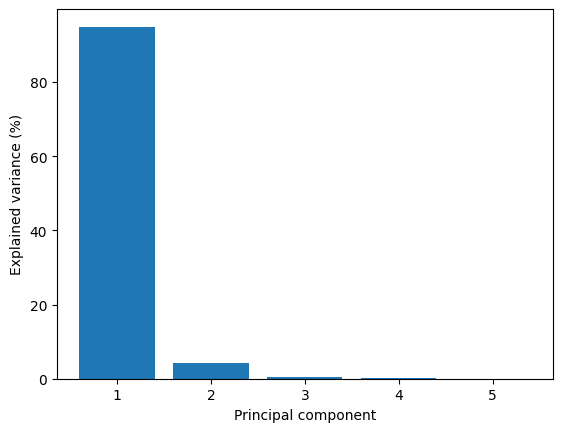

In [3]:
display(pd.DataFrame({'eigenvalue':r['eigenvalues'],'variance (%)':r['explained']}))
V = np.array(r['eigenvectors'])
C = np.array(r['covariance'])
print('Maximum eigen-equation error:', np.max(np.abs(C@V - V*np.array(r['eigenvalues']))))
plt.bar(range(1,len(r['explained'])+1),r['explained']); plt.xlabel('Principal component'); plt.ylabel('Explained variance (%)'); plt.show()

## 3. Least squares and model evaluation
Choose k by 5-fold cross-validation on training data. Report held-out scores for comparison, not model selection.

Selected components: 2


,key,components,variance,cv_rmse,mae,mse,rmse,r2
0,baseline,5,100.0000,1.8304,0.8293,0.8761,0.9360,0.9981
1,1,1,94.9365,1.7980,2.0145,5.4101,2.3260,0.9882
2,2,2,99.1783,1.0658,0.7541,0.7637,0.8739,0.9983
3,3,3,99.6749,1.1100,0.7836,0.7826,0.8846,0.9983
4,4,4,99.9815,1.2436,0.8666,0.9682,0.9840,0.9979
5,5,5,100.0000,1.8304,0.8293,0.8761,0.9360,0.9981


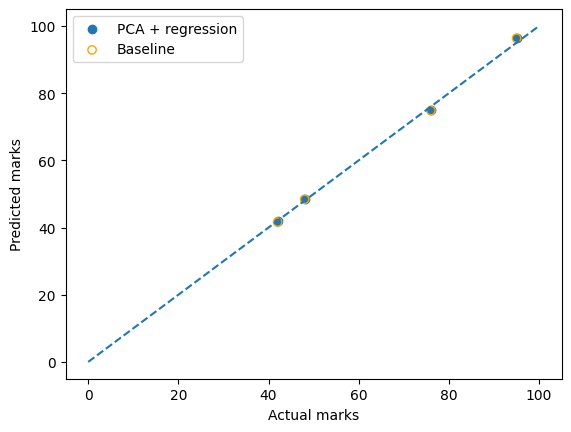

In [4]:
print('Selected components:',r['selected'])
display(pd.DataFrame(r['comparison']).round(4))
k=r['selected']; actual=r['actual']; pred=r['predictions'][k]
plt.scatter(actual,pred,label='PCA + regression'); plt.scatter(actual,r['predictions']['baseline'],facecolors='none',edgecolors='orange',label='Baseline'); lo=min(0,*pred,*r['predictions']['baseline']); hi=max(r['scale'],*pred,*r['predictions']['baseline']); plt.plot([lo,hi],[lo,hi],'--'); plt.xlabel('Actual marks'); plt.ylabel('Predicted marks'); plt.legend(); plt.show()

## 4. A worked prediction
A hypothetical record near the dataset median. This is not an assessment of a real student.

In [5]:
values={f:b['default'] if mode=='synthetic' else round(b['default']) for f,b in r['bounds'].items()}
p = predict(mode,r['selected'],values)
print(values)
print('Standardized:',np.round(p['standardized'],3))
print('PC scores:',np.round(p['pcs'],3))
print('Intercept + dot product:',p['intercept']+np.dot(p['pcs'],p['coefficients']))
print('Predicted grade:',round(p['prediction'],2),'/',r['scale'])

{'Study_Hours': 5.5, 'Attendance': 79.0, 'Previous_Marks': 59.0, 'Assignment_Marks': 64.0, 'Sleep_Hours': 7.0}
Standardized: [-0.032  0.04  -0.147 -0.14   0.07 ]
PC scores: [-0.098  0.13 ]
Intercept + dot product: 65.8348992168727
Predicted grade: 65.83 / 100


## 5. Limitations
The included 20-row synthetic dataset is strongly correlated and has only four held-out records. It cannot establish real-world accuracy. The UCI option uses 395 mathematics records from two Portuguese secondary schools, and the no-G1/G2 mode is a more difficult experiment. Predictions are not causal or suitable for grading/admissions. Source: https://doi.org/10.24432/C5TG7T (CC BY 4.0).